Helena Ruiz Cañas NIU:1704276

Aina Vidal Vazquez NIU:1709382

# Student Performance Predictions

El conjunt de dades escollit i que es presenta a continuació, tracta del rendiment estudiantil. L'objectiu principal és avaluar i predir els resultats dels estudiants en funció de diversos factors acadèmics i de comportament.

Aquest dataset conté al voltant de 1.000 registres i inclou valors aleatoris perduts i errors de dades intencionats per fer-la més realista per a la pràctica de neteja i preprocessament de dades.

Per tal de desenvolupar aquest projecte dividirem la feina en 5 apartats:

· Anàlisi exploratòria de dades (EDA).

· Preprocessament de les dades

· Selecció de les mètriques més adequades

· Entrenament i avaluació de models

· Conclusions finals

In [ ]:
#llibreria necessària
!pip install xgboost

## 1.EDA

Primer començarem amb la fase d'exploració de les dades, on es carrega el dataset i s'analitza de forma gràfica.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#llegir el dataframe i visualitzar
df = pd.read_csv("student_performance_updated_1000.csv")
df


,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
995,NaN,Kenneth Murray,Male,85.0,20.0,NaN,1.0,High,72.0,0.8,80.0,True
996,4497.0,Amy Stout,Female,91.0,NaN,86.0,0.0,High,90.0,3.9,80.0,True
997,1886.0,NaN,Male,85.0,8.0,82.0,2.0,Low,68.0,0.4,54.0,False
998,7636.0,Joseph Sherman,Male,88.0,17.0,60.0,2.0,High,85.0,0.9,53.0,True


In [69]:
#mirar info del df i la quantitat de nans
print ("=============INFO=================")
print(df.info())

print ("===========DESCRIBE===============")
print (df.describe())

#comprobar si nans
def buscarNans(df):
    return df.isna().sum().sum() > 0

print ("==================================")
print(f"Hi ha nans al df? {buscarNans(df)}  \n")


=============INFO=================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  960 non-null    float64
 1   Name                       966 non-null    object 
 2   Gender                     952 non-null    object 
 3   AttendanceRate             960 non-null    float64
 4   StudyHoursPerWeek          950 non-null    float64
 5   PreviousGrade              967 non-null    float64
 6   ExtracurricularActivities  957 non-null    float64
 7   ParentalSupport            978 non-null    object 
 8   FinalGrade                 960 non-null    float64
 9   Study Hours                976 non-null    float64
 10  Attendance (%)             959 non-null    float64
 11  Online Classes Taken       975 non-null    object 
dtypes: float64(8), object(4)
memory usage: 93.9+ KB
None
===========DESCRI

In [70]:
#buscar quin % de nans té cada columna
percentatgeNansCol = df.isna().mean(axis = 0)
print(f"% nans per columna: \n{percentatgeNansCol}\n")

#buscar quin % de nans té cada fila
percentatgeNansFil = df.isna().mean(axis = 1)
print(f"% nans per fila: \n{percentatgeNansFil}")

% nans per columna: 
StudentID                    0.040
Name                         0.034
Gender                       0.048
AttendanceRate               0.040
StudyHoursPerWeek            0.050
PreviousGrade                0.033
ExtracurricularActivities    0.043
ParentalSupport              0.022
FinalGrade                   0.040
Study Hours                  0.024
Attendance (%)               0.041
Online Classes Taken         0.025
dtype: float64

% nans per fila: 
0      0.000000
1      0.000000
2      0.000000
3      0.000000
4      0.083333
         ...   
995    0.166667
996    0.083333
997    0.083333
998    0.000000
999    0.083333
Length: 1000, dtype: float64


S'observen nans a totes les columnes del dataset, però els percentatges són bastant baixos pel que no hauria d'haver-hi problema a tractar-los.

In [71]:
#mirar quins son els minims i maxims de cada columna numèrica
minims = df.min(numeric_only=True)
maxims = df.max(numeric_only=True)
print(f"Minims de cada columna numèrica:\n{minims}\n")
print(f"Maxims de cada columna numèrica:\n{maxims}\n")

Minims de cada columna numèrica:
StudentID                     1.0
AttendanceRate               70.0
StudyHoursPerWeek             8.0
PreviousGrade                60.0
ExtracurricularActivities     0.0
FinalGrade                   62.0
Study Hours                  -5.0
Attendance (%)               50.0
dtype: float64

Maxims de cada columna numèrica:
StudentID                    9998.0
AttendanceRate                 95.0
StudyHoursPerWeek              30.0
PreviousGrade                  90.0
ExtracurricularActivities       3.0
FinalGrade                     92.0
Study Hours                     5.0
Attendance (%)                200.0
dtype: float64



Es pot veure que hi ha valors irregulars tant a Study Hours com a Attendance (%), ja que a la primera el mínim és un valor negatiu i a la segona el màxim és un valor superior a 100. Com tenim dues altres variables que ens donen la mateixa informació (StudyHoursPerWeek i AttendanceRate respectivament), simplement descartarem les que són irregulars, ja que si no ens podria donar problemes a l'hora de trobar relacions entre variables.

També es pot observar que el rang de les notes finals és molt petit, ja que va només de 62 a 92, el que pot donar problemes més endavant per fer prediccions.

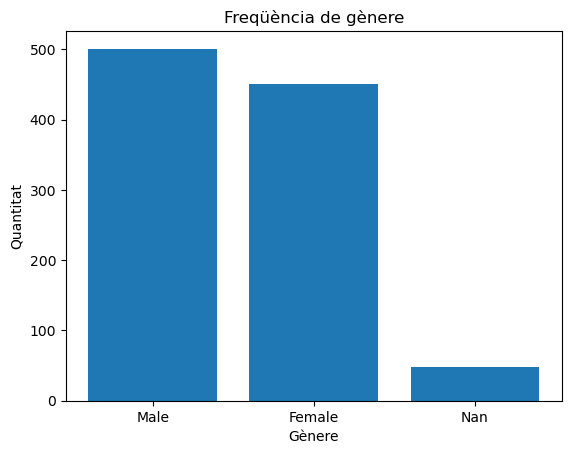

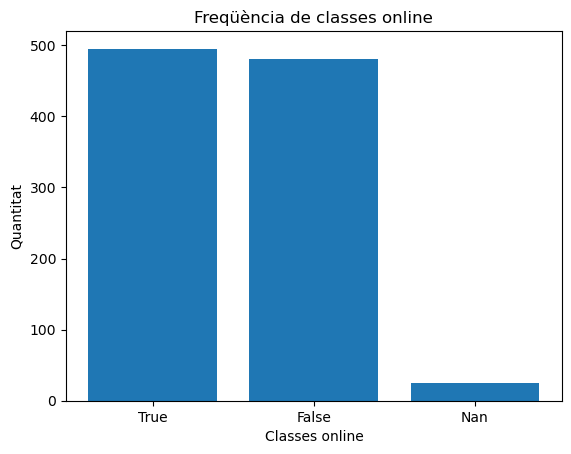

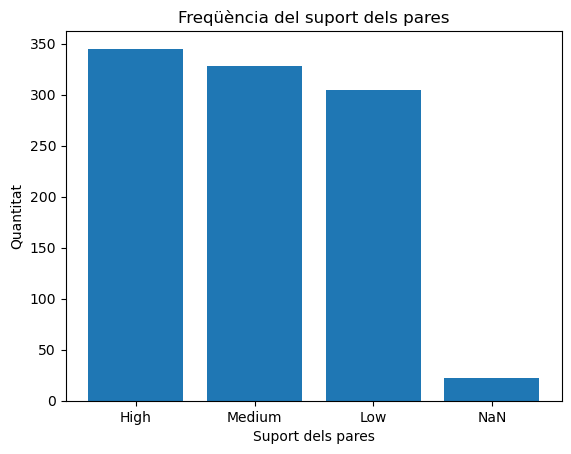

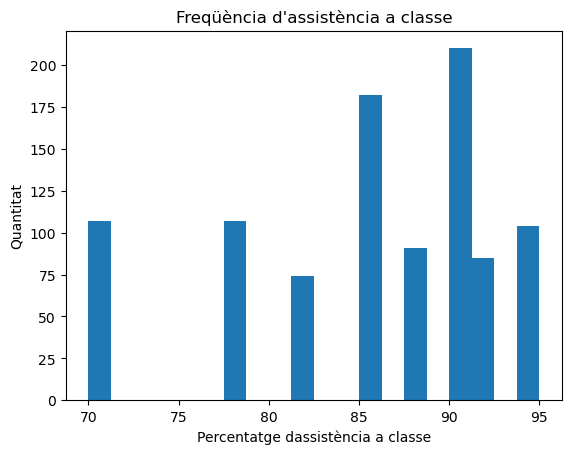

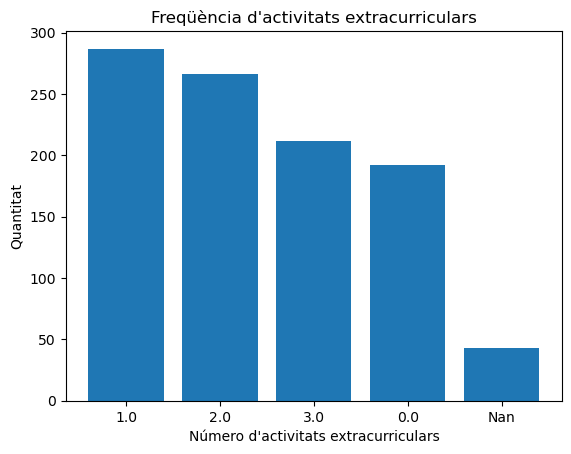

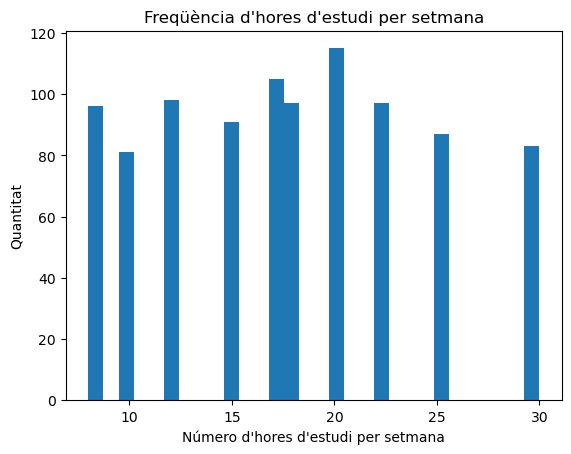

In [72]:
#Gràfiques per veure la distribució

#Gràfica atribut gender
gender_counts = df['Gender'].fillna('Nan').value_counts()
plt.bar(gender_counts.index, gender_counts.values)
plt.title("Freqüència de gènere")
plt.xlabel("Gènere")
plt.ylabel("Quantitat")
plt.show()

#Gràfica online classes taken
online_classes_count = df['Online Classes Taken'].fillna('Nan').value_counts()
plt.bar(online_classes_count.index.astype(str), online_classes_count.values)
plt.title("Freqüència de classes online")
plt.xlabel("Classes online")
plt.ylabel("Quantitat")
plt.show()

#Gràfica ParentalSupport
parentalS_counts = df['ParentalSupport'].fillna('NaN').value_counts()
plt.bar(parentalS_counts.index, parentalS_counts.values)
plt.title("Freqüència del suport dels pares")
plt.xlabel("Suport dels pares")
plt.ylabel("Quantitat")
plt.show()

#Gràfica AttendanceRate
plt.hist(df['AttendanceRate'].dropna(), bins=20)
plt.title("Freqüència d'assistència a classe")
plt.xlabel("Percentatge dassistència a classe")
plt.ylabel("Quantitat")
plt.show()

#Gràfica activitats extracurriculars
activitats_counts = df['ExtracurricularActivities'].fillna('Nan').value_counts()
plt.bar(activitats_counts.index.astype(str), activitats_counts.values)
plt.title("Freqüència d'activitats extracurriculars")
plt.xlabel("Número d'activitats extracurriculars")
plt.ylabel("Quantitat")
plt.show()

#Gràfica StudyHoursPerWeek
plt.hist(df['StudyHoursPerWeek'].dropna(), bins=30)
plt.title("Freqüència d'hores d'estudi per setmana")
plt.xlabel("Número d'hores d'estudi per setmana")
plt.ylabel("Quantitat")
plt.show()

Amb les gràfiques es pot veure que gairebé totes les variables estan molt balancejades, el que pot ser un problema més endavant si els models no troben bones relacions per fer prediccions amb fonaments.

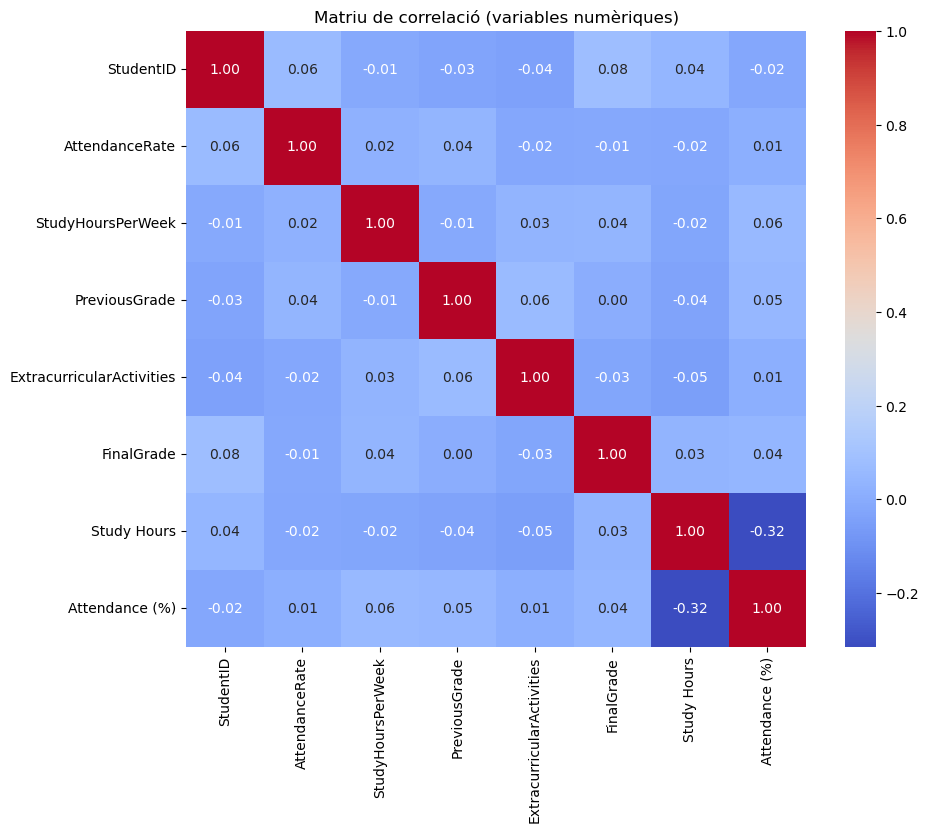

FinalGrade                   1.000000
StudentID                    0.078321
Attendance (%)               0.040807
StudyHoursPerWeek            0.036394
Study Hours                  0.031023
PreviousGrade                0.003982
AttendanceRate              -0.014768
ExtracurricularActivities   -0.026133
Name: FinalGrade, dtype: float64


In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

#seleccionem només les variables numèriques
var_num = df.select_dtypes(include=['int64', 'float64'])

#matriu de correlació
correlacio = var_num.corr()

plt.figure(figsize=(10,8))
sns.heatmap(correlacio, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriu de correlació (variables numèriques)")
plt.show()

#correlació amb FinalGrade
correlacio_FG = correlacio['FinalGrade'].sort_values(ascending=False)
print(correlacio_FG)

L’anàlisi de la correlació entre les variables numèriques i la variable objectiu FinalGrade mostra valors molt propers a zero per a totes les variables. Cap d’elles supera una correlació de 0.1, indicant que no existeixen relacions lineals significatives. El conjunt de dades conté massa soroll i no proporciona informació suficient per a la predicció de la nota final.

In [74]:
#mirar si hi ha alumnes repetits
alumne = df['Name'].value_counts()
repetits = alumne[alumne > 1]
print(f"Alumnes repetits: {repetits}")

Alumnes repetits: Name
Erica Miller         2
Kimberly Harrison    2
Andrea Frey          2
Anthony Smith        2
Name: count, dtype: int64


Veiem que hi ha quatre alumnes duplicats, per tant, mirarem si tenen les mateixes dades i podem ajuntar-los en una sola fila directament o si hem de processar les dades per trobar valors que s'ajustin a les dues instàncies.

In [75]:
#explorar alumnes repetits

df[df['Name']=='Erica Miller']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
946,9741.0,Erica Miller,Male,85.0,10.0,90.0,0.0,Low,85.0,4.5,98.0,False
950,4015.0,Erica Miller,Male,78.0,22.0,90.0,3.0,Low,80.0,4.4,100.0,False


In [76]:

df[df['Name']=='Kimberly Harrison']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
109,5497.0,Kimberly Harrison,Male,91.0,15.0,86.0,NaN,Medium,92.0,3.0,72.0,True
812,2120.0,Kimberly Harrison,NaN,92.0,17.0,77.0,3.0,Low,90.0,4.3,NaN,False


In [77]:
df[df['Name']=='Andrea Frey']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
45,3900.0,Andrea Frey,Female,85.0,10.0,88.0,0.0,Low,92.0,1.3,100.0,True
681,2253.0,Andrea Frey,Female,85.0,25.0,82.0,1.0,Medium,72.0,1.3,71.0,True


In [78]:
df[df['Name']=='Anthony Smith']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
237,5836.0,Anthony Smith,Male,92.0,30.0,90.0,0.0,Low,92.0,2.5,91.0,False
963,1019.0,Anthony Smith,Male,85.0,25.0,60.0,0.0,High,90.0,3.3,64.0,False


Es pot veure que alguns dels valors sí que coincideixen, però d'altres no, per tant, tractarem aquestes dades abans de fer tot el preprocessament del conjunt.

## 2. Preprocessament de les dades

A continuació, s'unificaran les files amb valors repetits fent la mitjana per tenir el dataset preparat, se separarà el train i el test, s'ompliran els valors Nan i s'aplicarà normalització.

In [79]:
#Unificar valors de files amb noms repetits

colsNumeriques = ['AttendanceRate', 'StudyHoursPerWeek', 'PreviousGrade', 'ExtracurricularActivities', 'FinalGrade', 'Study Hours', 'Attendance (%)']

#Erica Miller
for i in range(len(colsNumeriques)):
    col = colsNumeriques[i]
    mitjana = df[df['Name']=='Erica Miller'][col].mean()
    df.loc[df['Name']=='Erica Miller', col] = mitjana
df.loc[df['Name']=='Erica Miller', 'StudentID'] = 9741

#Kimberly Harrison
for i in range(len(colsNumeriques)):
    col = colsNumeriques[i]
    mitjana = df[df['Name']=='Kimberly Harrison'][col].mean()
    df.loc[df['Name']=='Kimberly Harrison', col] = mitjana
df.loc[df['Name']=='Kimberly Harrison', 'StudentID'] = 5497
df.loc[df['Name']=='Kimberly Harrison', 'Gender'] = 'Male'
df.loc[df['Name']=='Kimberly Harrison', 'ParentalSupport'] = 'Medium'
df.loc[df['Name']=='Kimberly Harrison', 'Online Classes Taken'] = 'True'

#Andrea Frey
for i in range(len(colsNumeriques)):
    col = colsNumeriques[i]
    mitjana = df[df['Name']=='Andrea Frey'][col].mean()
    df.loc[df['Name']=='Andrea Frey', col] = mitjana
df.loc[df['Name']=='Andrea Frey', 'StudentID'] = 3900
df.loc[df['Name']=='Andrea Frey', 'ParentalSupport'] = 'Medium'

#Anthony Smith
for i in range(len(colsNumeriques)):
    col = colsNumeriques[i]
    mitjana = df[df['Name']=='Anthony Smith'][col].mean()
    df.loc[df['Name']=='Anthony Smith', col] = mitjana
df.loc[df['Name']=='Anthony Smith', 'StudentID'] = 5836
df.loc[df['Name']=='Anthony Smith', 'ParentalSupport'] = 'Medium'


En el cas de la variable Gender de Erica Miller, com tenim un valor Male i l'altre nan, hem assignat el valor Male, ja que és el que ens dona més informació.

En el cas de les classes online de la Kimberly Harrison, com tenim un valor True i l'altre False, hem decidit que mirant els resultats acadèmics i la resta de dades, té més sentit que hagi fet alguna classe online, ja que són resultats prou alts.

En els casos de discrepàncies en la variable de suport parental, hem decidit fixar-la a Medium, ja que és un valor mig i com no sabem amb exactitud quin valor és, creiem que és la millor opció.

Un cop unificades les dades, ja es poden eliminar les files duplicades.

In [80]:
#Eliminar les files duplicades
df.drop_duplicates(subset=['Name'], keep='first', inplace=True)

In [81]:
df[df['Name']=='Erica Miller']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
946,9741.0,Erica Miller,Male,81.5,16.0,90.0,1.5,Low,82.5,4.45,99.0,False


In [82]:
df[df['Name']=='Kimberly Harrison']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
109,5497.0,Kimberly Harrison,Male,91.5,16.0,81.5,3.0,Medium,91.0,3.65,72.0,True


In [83]:
df[df['Name']=='Andrea Frey']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
45,3900.0,Andrea Frey,Female,85.0,17.5,85.0,0.5,Medium,82.0,1.3,85.5,True


In [84]:
df[df['Name']=='Anthony Smith']

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
237,5836.0,Anthony Smith,Male,88.5,27.5,75.0,0.0,Medium,91.0,2.9,77.5,False


In [85]:
#Eliminar columnes que no aporten info
cols_eliminar = ['StudentID', 'Name', 'Study Hours', 'Attendance (%)']
df = df.drop(cols_eliminar, axis=1)
df

,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Online Classes Taken
0,Male,85.0,15.0,78.0,1.0,High,80.0,False
1,Female,90.0,20.0,85.0,2.0,Medium,87.0,True
2,Male,78.0,10.0,65.0,0.0,Low,68.0,False
3,Male,92.0,25.0,90.0,3.0,High,92.0,False
4,Female,NaN,18.0,82.0,2.0,Medium,85.0,True
...,...,...,...,...,...,...,...,...
994,Male,78.0,20.0,60.0,0.0,High,62.0,False
995,Male,85.0,20.0,NaN,1.0,High,72.0,True
996,Female,91.0,NaN,86.0,0.0,High,90.0,True
998,Male,88.0,17.0,60.0,2.0,High,85.0,True


Eliminem les columnes de StudentID i de Name, ja que no aporten informació rellevant per saber la nota final dels alumnes.

Eliminem les columnes Study Hours i Attendance(%), ja que tenim dues altres variables (StudyHoursPerWeek i AttendanceRate) que aporten la mateixa informació i a més a més no tenen valors irregulars, per tant, hem decidit triar aquestes com a innecessàries.

In [86]:
#feature engineering
#crear columnes noves
df['StudentEngagement'] = df['StudyHoursPerWeek'] * (df['AttendanceRate'] / 100)
df['HighAttendance'] = (df['AttendanceRate'] > 85).astype(int)
df['HighStudyHours'] = (df['StudyHoursPerWeek'] > df['StudyHoursPerWeek'].median()).astype(int)
df['ManyActivities'] = (df['ExtracurricularActivities'] >= 2).astype(int)
df['StudyLoad'] = df['StudyHoursPerWeek'] + df['ExtracurricularActivities']

df

,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Online Classes Taken,StudentEngagement,HighAttendance,HighStudyHours,ManyActivities,StudyLoad
0,Male,85.0,15.0,78.0,1.0,High,80.0,False,12.75,0,0,0,16.0
1,Female,90.0,20.0,85.0,2.0,Medium,87.0,True,18.00,1,1,1,22.0
2,Male,78.0,10.0,65.0,0.0,Low,68.0,False,7.80,0,0,0,10.0
3,Male,92.0,25.0,90.0,3.0,High,92.0,False,23.00,1,1,1,28.0
4,Female,NaN,18.0,82.0,2.0,Medium,85.0,True,NaN,0,0,1,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,Male,78.0,20.0,60.0,0.0,High,62.0,False,15.60,0,1,0,20.0
995,Male,85.0,20.0,NaN,1.0,High,72.0,True,17.00,0,1,0,21.0
996,Female,91.0,NaN,86.0,0.0,High,90.0,True,NaN,1,0,0,NaN
998,Male,88.0,17.0,60.0,2.0,High,85.0,True,14.96,1,0,1,19.0


Com que a l'etapa EDA hem vist amb la matriu de correlacions que les variables tenen una correlació molt feble, apliquem feature engineering creant noves variables. StudentEngagement reflecteix el compromís de l'alumne basat en les hores d'estudi i l'assistència.

També hem creat variables binàries (thresholds) segons l'assistència, les hores d'estudi per setmana, el nombre d'activitats extracurriculars i calculant la càrrega total d'estudi.

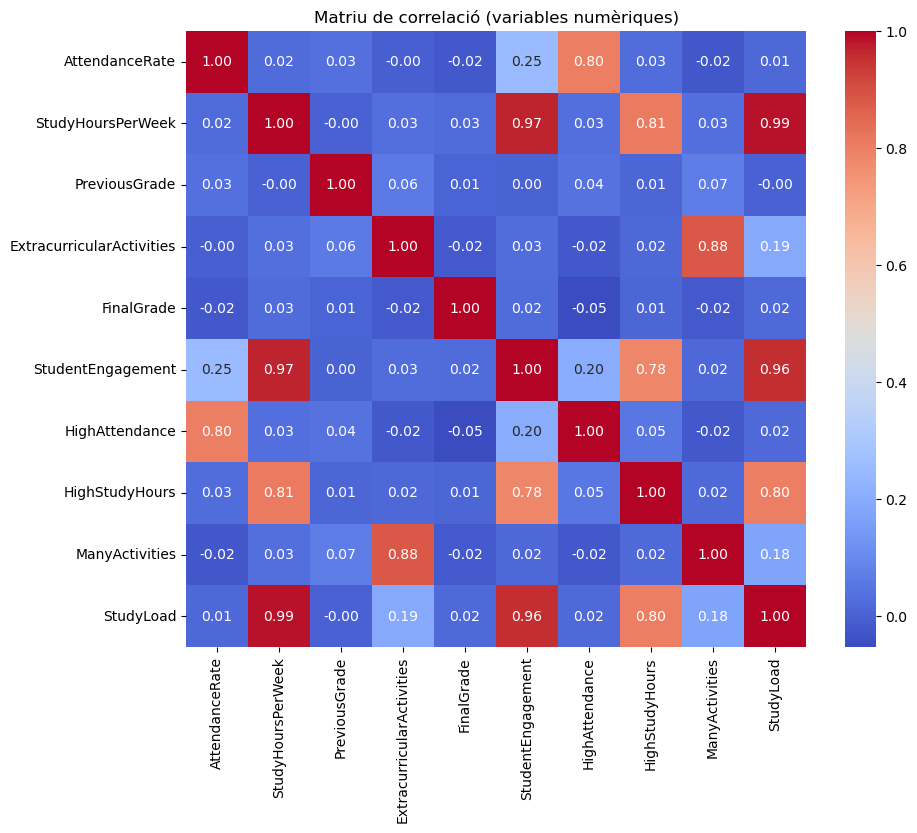

FinalGrade                   1.000000
StudyHoursPerWeek            0.025077
StudentEngagement            0.024401
StudyLoad                    0.018686
HighStudyHours               0.013386
PreviousGrade                0.006739
ManyActivities              -0.015338
ExtracurricularActivities   -0.018984
AttendanceRate              -0.023093
HighAttendance              -0.052291
Name: FinalGrade, dtype: float64


In [87]:
#seleccionem només les variables numèriques
var_num = df.select_dtypes(include=['int64', 'float64', 'int32'])

#matriu de correlació
correlacio = var_num.corr()

plt.figure(figsize=(10,8))
sns.heatmap(correlacio, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriu de correlació (variables numèriques)")
plt.show()

#correlació amb FinalGrade
correlacio_FG = correlacio['FinalGrade'].sort_values(ascending=False)
print(correlacio_FG)

Creant les noves columnes veiem que la correlació amb la variable objectiu FinalGrade segueix sent molt baixa. Com que des del principi la correlació entre les variables i amb la variable objectiu és molt baixa, és normal que combinant i reorganitzant tampoc aconseguim tenir-la.

In [88]:
#Separar en X i Y
atributs = []
for element in df.keys():
  if element != "FinalGrade":
    atributs.append(element)

Y = df['FinalGrade']
X = df[atributs]

In [89]:
#Separar train i test
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size = 0.3, random_state = 42)


In [90]:
#omplir nans
num_cols = df.select_dtypes(include=['float64','int64','int32']).columns.tolist()
num_cols.remove('FinalGrade')  #treiem la columna objectiu
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

#si son numèriques, fem la mitjana només amb el train
for col in num_cols:
    X_train[col] = X_train[col].fillna(X_train[col].mean())
    X_test[col] = X_test[col].fillna(X_train[col].mean())

Y_train = Y_train.fillna(Y_train.mean())
Y_test = Y_test.fillna(Y_train.mean())
    
#si son categòriques, fem la moda
for col in cat_cols:
    moda = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(moda)
    X_test[col] = X_test[col].fillna(moda)

#verifiquem que ja no tenim nans
print(f"Hi ha Nans a train? {buscarNans(X_train)}")
print(f"Hi ha Nans a test? {buscarNans(X_test)}")

X_train

Hi ha Nans a train? False
Hi ha Nans a test? False


C:\Users\Helena\AppData\Local\Temp\ipykernel_2660\1254360392.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(moda)


,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,Online Classes Taken,StudentEngagement,HighAttendance,HighStudyHours,ManyActivities,StudyLoad
231,Male,88.0,25.0,88.0,2.000000,Medium,True,22.00,1,1,1,27.000000
333,Male,85.0,10.0,88.0,2.000000,High,True,8.50,0,0,1,12.000000
890,Male,82.0,17.0,85.0,1.000000,High,True,13.94,0,0,0,18.000000
215,Female,92.0,15.0,85.0,1.000000,High,False,13.80,1,0,0,16.000000
79,Male,88.0,25.0,88.0,1.544892,Medium,False,22.00,1,1,0,18.934853
...,...,...,...,...,...,...,...,...,...,...,...,...
106,Male,88.0,17.0,82.0,1.000000,Medium,True,14.96,1,0,0,18.000000
273,Male,91.0,8.0,60.0,0.000000,Medium,True,7.28,1,0,0,8.000000
891,Female,70.0,12.0,60.0,3.000000,High,True,8.40,0,0,1,15.000000
450,Female,91.0,12.0,82.0,3.000000,High,True,10.92,1,0,1,15.000000


En aquest apartat omplim els nans amb la mitjana en el cas de les columnes numèriques i amb la moda en el cas de les categòriques. 
Per omplir tant els valors del train com els de test utilitzem la mitjana i la moda del train, per tal d'evitar problemes de data leakage.

In [91]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

#convertim a forma binària
X_train['Online Classes Taken'] = X_train['Online Classes Taken'].replace({'False': 0, 'True': 1})
X_train['Online Classes Taken'] = X_train['Online Classes Taken'].astype(int)
X_test['Online Classes Taken'] = X_test['Online Classes Taken'].replace({'False': 0, 'True': 1})
X_test['Online Classes Taken'] = X_test['Online Classes Taken'].astype(int)

#separem columnes numèriques i categòriques
num_cols = X_train.select_dtypes(include=['int64', 'float64','int32']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'bool', 'category']).columns.tolist()


# ColumnTransformer encoding + scale
ct = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols)
])

X_train_enc = ct.fit_transform(X_train)
X_test_enc  = ct.transform(X_test)

Les variables categòriques s'han convertit a format numèric amb OneHotEnconder, hem fet una normalització de les dades usant StandardScaler.

Ara que ja tenim les dades preprocessades i lliures de data leakage.

## 3. Selecció de les mètriques

Per validar aquest projecte hem triat tres mètriques que creiem que són les més adecuades pel problema que es presenta i les que ens faran trobar resultats més acurats i realistes, ja que mesuren coses diferents i per tant, es complementen.

La primera mètrica que farem servir és el coeficient de determinació (r2). Aquesta indica la proporció de variabilitat de la variable objectiu (el target), que és explicada pel model. Quan s'obté un r2 exactament igual a 1 vol dir que el model explica perfectament les dades, un valor igual a 0 indica que el model no millora respecte a predir la mitjana, i un valor inferior a 0 significa que el model fa pitjors prediccions que si utilitzessim la mitjana. L'hem triat perquè resulta fàcil fer comparacions entre models, però té la desavantatge que no indica exactament el tamay de l'error que s'està produint.

La segona mètrica triada és el MAE (Mean Absolute Error), el qual a comparació de l'r2, calcula la mitjana del valor absolut dels errors de les prediccions que ha realitzat el model. El valor és fàcil d'interpretar, ja que indica l'error mitjà sense aplicar cap penalització a valors extrems.

Per últim, també farem servir el RMSE (Root Mean Squared Error), que mesura l'arrel quadrada del MSE (Mean Squared Error). La diferència és que aquest sí que penalitza els valors extrems, i indica en quantes unitats s'ha equivocat el model de mitjana.

## 4. Entrenament

En aquest apartat s'entrenen diferents models de Machine Learning amb l'objectiu de predir la variable FinalGrade. Es comparen diverses tècniques per analitzar el rendiment i determinar quin model s'adapta millor a les dades.

In [92]:
# Regressió lineal
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train_enc, Y_train)

YpredTrain = lr.predict(X_train_enc)
YpredTest = lr.predict(X_test_enc)

#r2 score
r2_train = r2_score(Y_train, YpredTrain)
r2_test = r2_score(Y_test, YpredTest)

#MAE (mean absolute error) contra més baix millor
mae = mean_absolute_error(Y_test, YpredTest)

#RMSE
mse = mean_squared_error(Y_test, YpredTest)
rmse = np.sqrt(mse)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"r2 train {r2_train}")
print(f"r2 test {r2_test}")


MAE: 8.07201641190857
RMSE: 9.771365235822394
r2 train 0.019465404424859667
r2 test -0.050459142637615306


Realitzant l'entrenament amb Regressió Lineal, podem observar que els resultats són valors molt baixos. Fet que ens indica que la relació entre les característiques i la variable objectiu no és estrictament lineal. Per tant provarem amb Random Forest per veure relacions no lineals.

In [93]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_enc, Y_train)

YpredTrain = rf.predict(X_train_enc)
YpredTest  = rf.predict(X_test_enc)

#r2 score
r2_train = r2_score(Y_train, YpredTrain)
r2_test = r2_score(Y_test, YpredTest)

#MAE (mean absolute error)
mae = mean_absolute_error(Y_test, YpredTest)

#RMSE
mse = mean_squared_error(Y_test, YpredTest)
rmse = np.sqrt(mse)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"r2 train {r2_train}")
print(f"r2 test {r2_test}")

MAE: 8.430479437385953
RMSE: 10.200340821437022
r2 train 0.8462159952171671
r2 test -0.14471675037077936


Al entrenar el model amb Random Forest, veiem que s'ajusta massa a les dades d'entrenament i no generalitza prou a dades noves. Això és un clar cas d'overfitting.

In [94]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(X_train_enc, Y_train)

YpredTrain = gbr.predict(X_train_enc)
YpredTest  = gbr.predict(X_test_enc)

#r2 score
r2_train = r2_score(Y_train, YpredTrain)
r2_test = r2_score(Y_test, YpredTest)

#MAE (mean absolute error)
mae = mean_absolute_error(Y_test, YpredTest)

#RMSE
mse = mean_squared_error(Y_test, YpredTest)
rmse = np.sqrt(mse)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"r2 train {r2_train}")
print(f"r2 test {r2_test}")

MAE: 8.400121606329643
RMSE: 10.040346466320004
r2 train 0.29978697502549534
r2 test -0.1090881643249717


En el Gradient Boosting Regressor veiem un ajust més moderat en les dades d'entrenament en comparació amb el Random Forest. Però el conjunt de test dona un valor negatiu i per tant, no aconsegueix generalitzar correctament.

In [95]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor()
knn.fit(X_train_enc, Y_train)

YpredTrain = knn.predict(X_train_enc)
YpredTest  = knn.predict(X_test_enc)

#r2 score
r2_train = r2_score(Y_train, YpredTrain)
r2_test = r2_score(Y_test, YpredTest)

#MAE (mean absolute error)
mae = mean_absolute_error(Y_test, YpredTest)

#RMSE
mse = mean_squared_error(Y_test, YpredTest)
rmse = np.sqrt(mse)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"r2 train {r2_train}")
print(f"r2 test {r2_test}")

MAE: 8.74134305333862
RMSE: 10.674484848955402
r2 train 0.25440267410063055
r2 test -0.2536102144244037


El model K-NN obté un rendiment baix tant en entrenament com en test. Aquest enfocament no és adient pel nostre conjunt de dades.

In [96]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb.fit(X_train_enc, Y_train)

YpredTrain = xgb.predict(X_train_enc)
YpredTest = xgb.predict(X_test_enc)

#r2 score
r2_train = r2_score(Y_train, YpredTrain)
r2_test = r2_score(Y_test, YpredTest)

#MAE (mean absolute error)
mae = mean_absolute_error(Y_test, YpredTest)

#RMSE
mse = mean_squared_error(Y_test, YpredTest)
rmse = np.sqrt(mse)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"r2 train {r2_train}")
print(f"r2 test {r2_test}")

MAE: 8.879131626124778
RMSE: 10.932035044730146
r2 train 0.8242997640379122
r2 test -0.3148333231525309


Novament, el model amb XGBoost, al igual que amb Random Forest, veiem que sestà produint overfitting. S'ajusta massa a les dades d'entrenament i no generalitza prou a dades noves.

In [97]:
from sklearn.ensemble import ExtraTreesRegressor

ext = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=42
)

ext.fit(X_train_enc, Y_train)

YpredTrain = ext.predict(X_train_enc)
YpredTest = ext.predict(X_test_enc)

#r2 score
r2_train = r2_score(Y_train, YpredTrain)
r2_test = r2_score(Y_test, YpredTest)

#MAE (mean absolute error)
mae = mean_absolute_error(Y_test, YpredTest)

#RMSE
mse = mean_squared_error(Y_test, YpredTest)
rmse = np.sqrt(mse)

print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"r2 train {r2_train}")
print(f"r2 test {r2_test}")


MAE: 9.061998234187136
RMSE: 11.082346931107343
r2 train 0.9946063413524443
r2 test -0.3512389484390892


Extra Trees Regressor també indica que s'està produint overfitting. Veiem un ajust gairebé perfecte en el conjunt d'entrenament, mentre que el conjunt de test és el pitjor dels models analitzats.

In [98]:
#Comparació i elecció millor model amb validació creuada
from sklearn.model_selection import cross_val_score

models = {
    "Regressió lineal": LinearRegression(),
    "Random forest regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient boosting regressor": GradientBoostingRegressor(random_state=42),
    "KNN": KNeighborsRegressor(),
    "XGB": XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
    ),
    "Extra trees regressor": ExtraTreesRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=42
    )
}

results = {}

#Validació creuada (cv=5) per a cada model
for name, model in models.items():
    scores = cross_val_score(model, X_train_enc,Y_train, cv=5, scoring= "r2")
    results[name] = scores
    print(f"{name} -> r2: {scores.mean():.4f}")

results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "r2 (cv=5)": [scores.mean() for scores in results.values()],
}).sort_values(by="r2 (cv=5)", ascending=False)

display(results_df)

Regressió lineal -> r2: -0.0219
Random forest regressor -> r2: -0.1272
Gradient boosting regressor -> r2: -0.1395
KNN -> r2: -0.1947
XGB -> r2: -0.2132
Extra trees regressor -> r2: -0.2619


,Model,r2 (cv=5)
0,Regressió lineal,-0.021898
1,Random forest regressor,-0.127166
2,Gradient boosting regressor,-0.139500
3,KNN,-0.194720
4,XGB,-0.213202
5,Extra trees regressor,-0.261863


## 5.Conclusions

En aquesta treball s’han analitzat diverses tècniques de regressió utilitzant el conjunt de dades "Student Performance Predictions", amb l’objectiu de predir la nota final del estudiants a partir de diverses variables acadèmiques i personals. El desenvolupament del projecte s’ha estructurat en diferents etapes: anàlisi exploratòria de dades, preprocessament, selecció de mètriques i entrenament de models.

En primer lloc, durant l’anàlisi exploratòria de les dades (EDA) s’ha estudiat l’estructura del dataset, detectant la presència de valors nuls, valors inconsistents i duplicats. També s’han analitzat les distribucions de les variables i la seva relació amb la variable objectiu mitjançant gràfiques i una matriu de correlació. Amb aquest anàlisi hem pogut observar que la majoria de variables presenten una correlació molt fluixa amb la nota final, fet que dificulta la predicció.

A continuació, en l’etapa de preprocessament, s’han aplicat diverses tècniques per preparar les dades abans de l’entrenament dels models. S’han unificat files duplicades, s’han omplert els valors nuls utilitzant la mitjana per a les variables numèriques i la moda per a les categòriques, i s’han convertit les variables categòriques en numèriques mitjançant tècniques d’encoding. També s’ha realitzat la separació entre variables explicatives i variable objectiu, així com la divisió en conjunts d’entrenament i test. Addicionalment, s’han explorat tècniques de feature engineering, sempre evitant produir data leakage.

Abans de l’entrenament, s’ha dut a terme una selecció de mètriques adequada al problema de regressió. S’han escollit el coeficient de determinació (r2), el MAE i el RMSE. El r2 facilita la comparació entre models i indica la capacitat explicativa del model, mentre que el MAE i el RMSE permeten quantificar l’error de predicció en unitats reals. El RMSE és especialment útil per detectar errors grans.

En l’etapa d’entrenament s’han provat diversos models de regressió, incloent la regressió lineal, Random Forest, Gradient Boosting, KNN, Extra Trees i XGBoost. Els resultats obtinguts mostren que, tot i que alguns models aconsegueixen un bon ajustament en el conjunt d’entrenament, el rendiment sobre el conjunt de test és generalment baix, amb valors de r2 negatius o propers a zero. Això indica problemes d’overfitting i una escasa capacitat de generalització.

Finalment, es pot concloure que el conjunt de dades presenta un alt nivell de soroll i poques relacions significatives entre les variables explicatives i la variable objectiu. El rang limitat de la nota final i la feble correlació entre les variables fan que els models no puguin aprendre patrons robustos. 

Tot i això, la pràctica ens ha semblat molt útil per consolidar conceptes fonamentals del machine learning, com ara l’anàlisi exploratòria, el preprocessament de dades, la selecció de mètriques, l’entrenament de diferents models i la detecció de problemes com l’overfitting i el data leakage.